# Lab 1 — Student workbook: ECG signals to features to a classifier
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/junjiechen-chris/CDT-HDS-ECG-Lab-1/blob/main/ECG_Preprocessing.ipynb)

**Learning outcomes:** read an ECG waveform and name its waves; calculate heart rate, SDRR and RMSSD from an RR sequence; code a naive beat detector and grow it, one step at a time, into a detector scored against NeuroKit2; train and evaluate a classifier on a full feature set.

**How to work:** run the supplied demonstrations and complete the cells marked **YOUR CODE**. Every task is a function, checked against a reference. Unfinished exercises print a reminder rather than stopping the demonstrations. Passing a numerical self-check verifies arithmetic, not the accuracy of detected beats.

The manual pipeline uses NumPy/SciPy on the same **300 Hz PhysioNet/CinC 2017** recordings as Lab 2. Sections 2 and 3 use NeuroKit2's beats, heart rate and RMSSD as the **NeuroKit2 reference**; it is not ground truth. Section 4 uses NeuroKit2 to extract features. Recording labels do not annotate individual beats. Educational use only.

| Question | Your work | Evidence to retain |
|---|---|---|
| 1. What is an ECG signal? | Label the P, Q, R, S and T dots on five excerpts | The five sequences, with the check passed |
| 2. What is measured from it? | Code heart rate, SDRR and RMSSD from NeuroKit2's RR sequences | `rhythm_features` passing the check; the three-row table |
| 3. Can we extract them ourselves? | Code a naive peak-finding detector, then a QRS-searching detector in three steps and median imputation, each scored against NeuroKit2 | `naive_beats`, `bandpass`, `differentiate` and `envelope`, `locate` and `correct` passing their checks; the leaderboard |
| 4. What are the features for? | Code a RandomForest on the 54 NeuroKit2 features, on Lab 2's split | `train_forest` passing the check; the test report; your test macro F1 |


## Setup
**On Colab:** open this notebook with the badge above, then **File → Save a copy in Drive** so that your work is kept. The cell below clones the repository (the helper code and requirements), downloads the data zip and asks for its **password, which is given in the lab**. Runtime: a CPU is enough.

**Locally:** clone the repository, create a virtual environment, `pip install -r requirements.txt -r requirements-comparison.txt`, and download the data zip into `data/`; the cell below unpacks it. See `README.md`.

The data are two pickle files: `ECG.pkl` (2,000 single-lead recordings at 300 Hz, PhysioNet/CinC 2017) and `ECG_feature.pkl` (the Section 4 feature table). Pickle can execute code: the loader has a trust flag, enabled here because the zip comes from the lab's own release.


In [1]:
import sys
from pathlib import Path

REPO_URL = "https://github.com/junjiechen-chris/CDT-HDS-ECG-Lab-1.git"
DATA_ZIP_URL = "https://huggingface.co/datasets/junjiechen-chris/CDT-HDS-ECG-Lab-1-data/resolve/main/ECG_lab_data.zip"

# On Colab the notebook opens alone: fetch the repository next to it and work inside it.
if not Path("code/shared_ecg.py").exists():
    import subprocess
    repo = Path(REPO_URL.rsplit("/", 1)[1].removesuffix(".git"))
    if not repo.exists():
        subprocess.run(["git", "clone", "--quiet", REPO_URL], check=True)
    import os; os.chdir(repo)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt",
                    "-r", "requirements-comparison.txt"], check=True)
sys.path.insert(0, str(Path("code").resolve()))

# The data: a password-protected zip with ECG.pkl and ECG_feature.pkl, unpacked into data/.
DATA_DIR = Path("data")
if not (DATA_DIR / "ECG.pkl").exists():
    import getpass, urllib.request, zipfile
    zip_path = DATA_DIR / "ECG_lab_data.zip"
    if not zip_path.exists():
        print("Downloading the data zip ...")
        urllib.request.urlretrieve(DATA_ZIP_URL, zip_path)
    password = getpass.getpass("Password for the data zip (given in the lab): ")
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(DATA_DIR, pwd=password.encode())
    print("Data unpacked into", DATA_DIR.resolve())

import numpy as np
import matplotlib.pyplot as plt
from shared_ecg import (FS, LABELS, DEFAULT_DATA, load_dataset, signal_mv, example_ids,
                        plot_beats, plot_traces, shade_regions)

DATA_PATH = DEFAULT_DATA  # data/ECG.pkl
TRUST_DATA_SOURCE = True  # The zip is the lab's own release; only enable for a trusted source.
ecg_data = load_dataset(DATA_PATH, trusted=TRUST_DATA_SOURCE)
candidates = example_ids(ecg_data)
print("Recordings:", len(ecg_data))
print({label: sum(r["label"] == label for r in ecg_data.values()) for label in LABELS})
print("Starting candidates (not quality-verified):", candidates)
plt.rcParams.update({"figure.figsize": (12, 3), "axes.grid": True})


Recordings: 2000
{'N': 1187, 'A': 196, 'O': 553, '~': 64}
Starting candidates (not quality-verified): {'N': 'A00001', 'A': 'A00004', 'O': 'A00008', '~': 'A00022'}


## 1. Inspect — what counts as one heartbeat?
Start with an **N-labelled** candidate. An N label does not guarantee clean data or normality of every beat. Look for visible P/QRS/T components, baseline changes, and noise.

Inspect the whole recording, then a short excerpt. All later stages use the **full signal**, not just the displayed window.


A00001 Normal sinus rhythm 30.0 s, 300 Hz


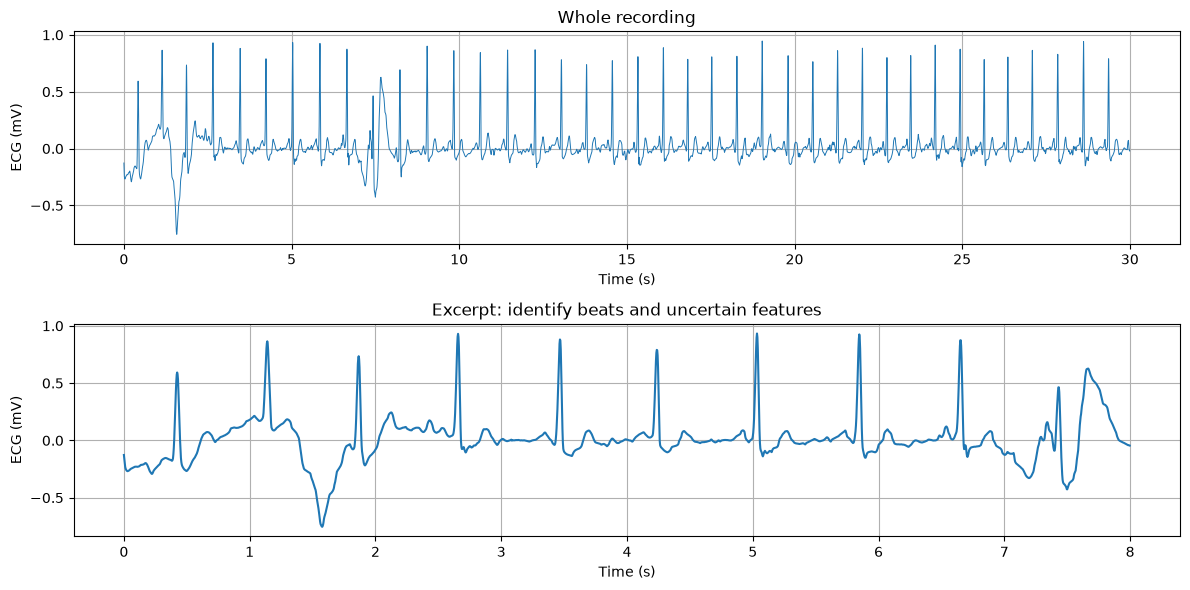

In [2]:
example_label = "N"  # Later try "A", "O", or "~", then rerun subsequent cells.
record_id = candidates[example_label]  # Or enter another reviewed ID.
if record_id is None:
    raise ValueError(f"No {example_label}-labelled recording in this export")
raw = signal_mv(ecg_data[record_id])  # Stored values / 1000 -> mV, as in Lab 2.
t = np.arange(len(raw)) / FS
start_s, end_s = 0.0, min(8.0, len(raw) / FS)
view = (t >= start_s) & (t < end_s)
if not np.any(view):
    raise ValueError("Choose a plotting window inside the recording")
print(record_id, LABELS[ecg_data[record_id]["label"]], f"{len(raw)/FS:.1f} s, {FS} Hz")
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(t, raw, lw=0.7)
axes[0].set_title("Whole recording")
axes[1].plot(t[view], raw[view])
axes[1].set_title("Excerpt: identify beats and uncertain features")
for ax in axes: ax.set(xlabel="Time (s)", ylabel="ECG (mV)")
plt.tight_layout(); plt.show()


### Task 1 — Label the waves · YOUR CODE
Six excerpts from N-labelled recordings, each with ten consecutive wave points of two beats marked as dots. The first is labelled as the example: its dots read **P Q R S T P Q R S T**. The other five start at a different wave of the cycle, so read each from the shape of the signal, not from the position: a small round bump before a sharp spike is a P wave, a broad bump after it is a T wave; the spike itself is R, with the small dip just before it Q and the dip just after it S.

**Deliver:** for diagrams 1 to 5, the ten letters in order, with the check passed. The check says which dots are wrong; it never prints the answer.


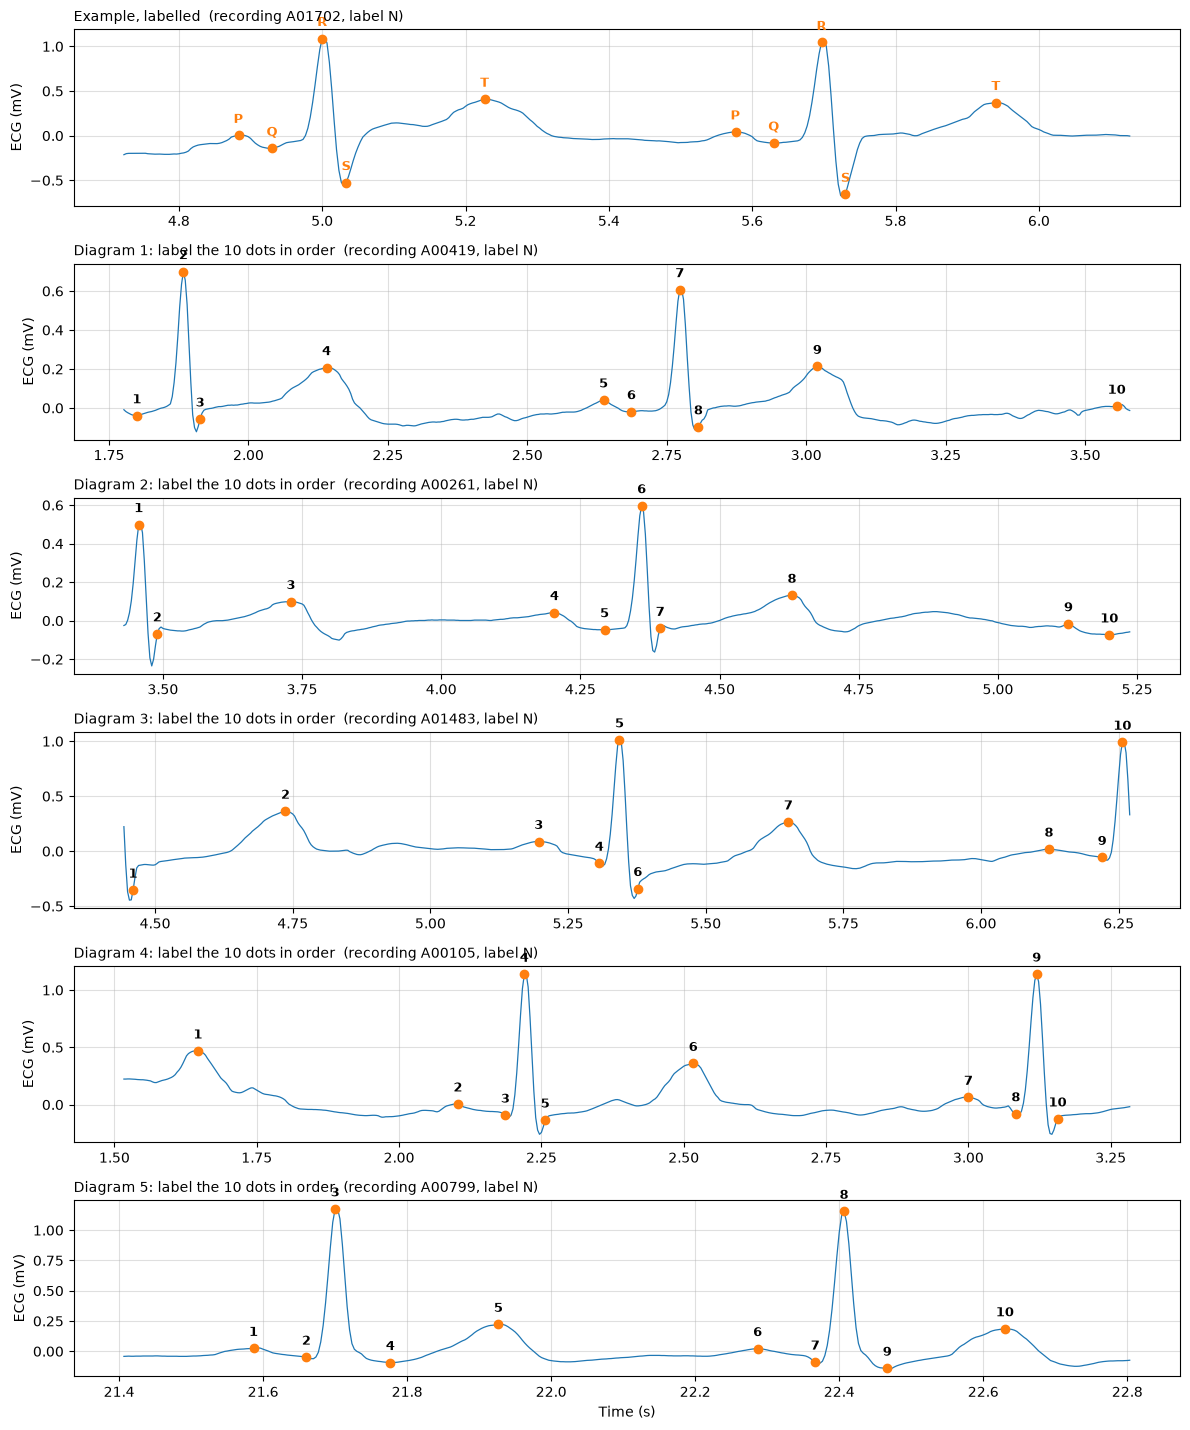

Diagram 1: no answer yet.
Diagram 2: no answer yet.
Diagram 3: no answer yet.
Diagram 4: no answer yet.
Diagram 5: no answer yet.


False

In [3]:
from wave_labels import show_wave_diagrams, check_wave_labels

show_wave_diagrams(ecg_data)

# YOUR CODE: ten letters per diagram, in the order of the numbered dots, e.g. "Q R S T P Q R S T P".
answers = {1: None, 2: None, 3: None, 4: None, 5: None}

check_wave_labels(answers)


## 2. Measuring rhythm from ECG signals
Clinicians and wearables describe the rhythm of the heart by the **times** of its beats, not by the shape of the waves: the RR intervals between consecutive R peaks, their average (the heart rate), and how much they change from one beat to the next (heart rate variability, HRV). The two HRV numbers used most are **SDRR**, the spread of the intervals, and **RMSSD**, the typical change from one interval to the next; RMSSD is the one that separates atrial fibrillation from normal rhythm. The lab note's Section 2 defines them and walks the whole route once, from raw signal to beats to intervals to these numbers, with NeuroKit2 finding the beats. Here you implement the arithmetic on real RR sequences and check it against NeuroKit2.


### Task 2 — Heart rate, SDRR and RMSSD from an RR sequence · YOUR CODE
NeuroKit2 finds the beats of a recording (`ecg_clean`, then `ecg_peaks`). The **RR sequence** is the differences between consecutive beat times, in seconds, and it is given to you below. Implement `rhythm_features`, which turns an RR sequence into the three numbers of the lab note's Section 2 (heart rate, SDRR and RMSSD).

**Specification: `rhythm_features(rr_s)`**
- **Given:** `rr_s`, a 1-D NumPy array of RR intervals in **seconds**, in time order: about 40 values for a 30 s recording, typically between 0.6 and 1.2 s. It comes from NeuroKit2's beats as `np.diff(beats) / FS`.
- **You may use:** NumPy only: the mean, the standard deviation with `ddof=1`, differences between neighbouring values, the square root.
- **Return:** a tuple of three floats `(heart_rate_bpm, sdrr_ms, rmssd_ms)`: heart rate = 60 / mean RR; SDRR = the sample standard deviation of the intervals in ms; RMSSD = the square root of the mean of the squared differences between successive intervals in ms (square *before* averaging, so that positive and negative changes do not cancel).
- **Checked by:** NeuroKit2's own `hrv_time` on the same beats, for three recordings, to six significant figures.

The cell runs your function on the three recordings of the lab note's figures (N, A and O) and checks each value against NeuroKit2's own `hrv_time` on the same beats (`HRV_MeanNN`, `HRV_SDNN`, `HRV_RMSSD`). NeuroKit2 calls SDRR *SDNN* whether or not the intervals were checked: a library's feature name tells you the formula, not that its assumptions hold.

**Deliver:** the function with the check passed, and the three-row table it prints.


In [4]:
from benchmark import neurokit_beats, neurokit_hrv  # NeuroKit2's ecg_clean + ecg_peaks, and hrv_time.

def rhythm_features(rr_s):
    """Return (heart_rate_bpm, sdrr_ms, rmssd_ms) from consecutive RR intervals in seconds."""
    rr_s = np.asarray(rr_s, dtype=float)
    heart_rate_bpm = None  # YOUR CODE: heart rate in bpm.
    rr_ms = None           # YOUR CODE: the intervals in milliseconds.
    sdrr_ms = None         # YOUR CODE: SDRR in ms.
    rmssd_ms = None        # YOUR CODE: RMSSD in ms.
    if any(value is None for value in (heart_rate_bpm, rr_ms, sdrr_ms, rmssd_ms)):
        return None
    return heart_rate_bpm, sdrr_ms, rmssd_ms

examples = {"N": "A00001", "A": "A00004", "O": "A00539"}  # The recordings of the lab note's figures.
nk_beats = neurokit_beats(raw)       # Your recording's beats, used again in Task 3 and 4A.
nk_values = neurokit_hrv(nk_beats)
print(f"{'':3}{'recording':<10}{'heart rate (bpm)':>18}{'SDRR (ms)':>12}{'RMSSD (ms)':>12}")
for label, rid in examples.items():
    beats = neurokit_beats(signal_mv(ecg_data[rid]))
    rr_s = np.diff(beats) / FS       # The RR sequence: consecutive beat times, in seconds.
    mine = rhythm_features(rr_s)
    if mine is None:
        print("Task 2: complete the four expressions, then rerun this cell.")
        break
    reference = neurokit_hrv(beats)
    np.testing.assert_allclose(mine, [reference["hr_bpm"], reference["sdnn_ms"], reference["rmssd_ms"]],
                               rtol=1e-6, err_msg=f"{rid}: differs from NeuroKit2's hrv_time on the same beats")
    print(f"{label:<3}{rid:<10}{mine[0]:18.1f}{mine[1]:12.1f}{mine[2]:12.1f}")
else:
    print("Task 2 check passed: NeuroKit2's hrv_time gives the same three numbers on all three recordings.")


   recording   heart rate (bpm)   SDRR (ms)  RMSSD (ms)
Task 2: complete the four expressions, then rerun this cell.


## 3. Extracting rhythm features from noisy raw signals
In this section you will learn to extract two rhythm features, heart rate and RMSSD, from noisy raw ECG signals. The route is always the same: find the beats, then pass their times to the `rhythm_features` you wrote in Task 2. The work is finding the beats, and we go through it in four steps:
1. We use NeuroKit2, an established ECG library, as a **reference beat detector** (3.1).
2. We implement a **naive peak-finding** beat detector: a threshold on the raw signal (3.2, Task 3).
3. We implement a detector that **searches for the QRS complex** instead of peaks, in three steps: filter, emphasise fast changes, locate the R peak (3.3, Tasks 4A–4C).
4. We add **median imputation**, which uses the rhythm itself to drop extra beats and fill in missed ones, and so corrects the HRV estimate (3.4, Task 4D).

At steps 2 to 4 we measure how well our detector agrees with the NeuroKit2 reference: its beats, and the heart rate and RMSSD computed from them, across every recording in the dataset. The settings are teaching choices for 300 Hz data, not a validated clinical detector.

### 3.1 NeuroKit2: a reference beat detector
**The NeuroKit2 reference.** NeuroKit2 is an open-source library used across research and industry to turn an ECG into beats and features, and its default pipeline (`ecg_clean`, then `ecg_peaks`) belongs to the same family as the detector you build in this section: filter, emphasise the fast QRS, threshold, place the beat. The reference is what NeuroKit2 gives for every recording, as it is: its beats, with no correction, and the heart rate and RMSSD calculated from them (`hrv_time`, as in Task 2). Two things to keep in mind. This dataset labels each recording's rhythm, but no one has marked the individual beats, so there is no ground truth: the reference is an established pipeline, **not the truth**, and a gap to it means *different*. And both detectors can make the same mistake, which no score can see.

**The evaluation.** In each of Tasks 3 and 4A to 4D you write one function from its description; a detector is the set of functions so far, kept in a dictionary (`steps_naive`, then `steps_4a = {**steps_naive, "filter": bandpass}`, and so on). `bench.score(name, steps)` runs a detector on every recording, prints three scores against the NeuroKit2 reference, enters it on the **leaderboard** and plots it next to the reference:
- **Beat agreement:** beats paired with a reference beat within ±100 ms, as 2 × matched / (our beats + reference beats). 1 means every beat pairs; missed and extra beats both lower it.
- **Heart rate error:** for each recording, |our heart rate − the reference's|, summarised by the **MAE** (mean absolute error, the typical error) and the **P95** (the error that only the worst 5% of recordings exceed).
- **RMSSD error:** the same for RMSSD, in ms.

The reference scores agreement 1 and errors 0. Recordings where our detector finds too few beats for a value (two for heart rate, three for RMSSD) are counted, not scored.


In [5]:
from benchmark import Benchmark
from shared_ecg import run_detector, median_rate_bpm

# The NeuroKit2 reference: its beats, heart rate and RMSSD for every recording, as it is (about 30 s).
# bench.score(name, steps) runs your detector on every recording, prints its scores, enters it
# on the leaderboard and shows it on your recording and on contrast_id, next to the reference. Pairing tolerance: 100 ms.
contrast_id = "A00726"  # The N-labelled recording that the lab note follows through every step.
bench = Benchmark(ecg_data, show=(record_id, contrast_id), tolerance_s=0.1)

NeuroKit2 reference beats for 2000 recordings; 1996 with at least three are scored.


The circles are NeuroKit2's beats on the two recordings shown at every step; the titles give the heart rate and RMSSD that its `hrv_time` calculates from them. Below them are the reference's values for every recording, by label.


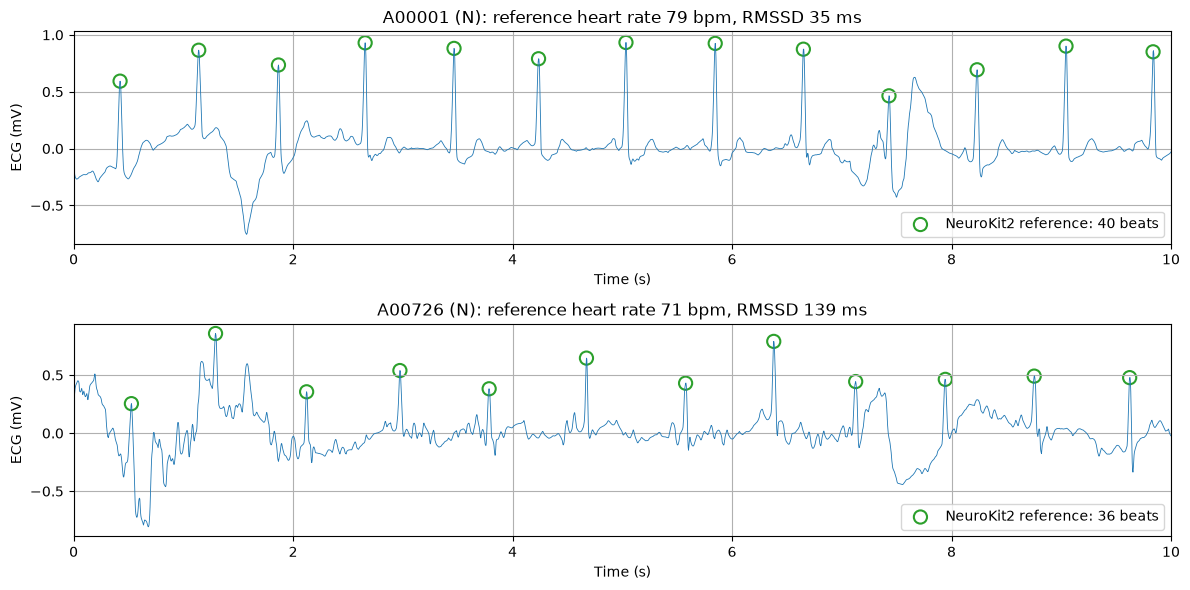

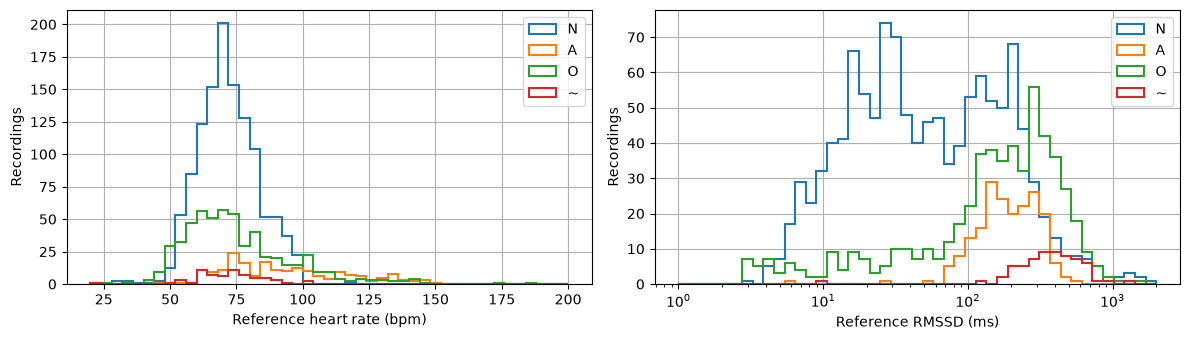

Median reference values by label (heart rate bpm, RMSSD ms): N 71, 49 | A 89, 188 | O 71, 181 | ~ 73, 394


In [6]:
bench.show_neurokit_reference()

### 3.2 A naive peak-finding detector
**The peak finder.** The QRS is the fastest and usually the tallest event of each beat (Section 1), so a peak finder emphasises fast changes, thresholds the result, and places one beat in each region above the threshold, at the R peak. The simplest peak finder is the threshold alone, and it is the first version of your detector, **detector v1**.

#### Task 3 — Code detector v1, the naive detector · YOUR CODE
Write `naive_beats`, which takes an ECG signal and a threshold (in mV) and returns the sample index of each beat: one beat per region where the signal is above the threshold, at the region's highest sample. Beat time in seconds is index / `FS`.

**Specification: `naive_beats(signal, threshold)`**
- **Given:** `signal`, a 1-D NumPy array of one ECG lead in **mV**, one value per sample at `FS` = 300 Hz (9,000 samples for 30 s); `threshold`, one number in mV. The signal rises above the threshold at every QRS complex, and sometimes at a tall T wave or an artefact; each crossing is a run of consecutive samples above it, a **region**, a few samples to a few tens of samples long.
- **You may use:** NumPy only: comparisons, padding, differences between neighbouring values, finding the positions of non-zero values, slicing, and the position of a maximum.
- **Return:** a 1-D integer NumPy array of **sample indices**, one per region, at the region's highest sample, in increasing order; empty if nothing crosses. Beat time in seconds = index / `FS`.
- **Checked by:** the invented signal `[0, 1, 3, 1, 0, 0, 2, 5, 2, 0, 1, 0]` with threshold 1.5, which must give `[2, 7]`; and a reference implementation on your recording.

The cell checks your function on a tiny invented signal and against a reference on your recording, then shows your beats with the threshold, next to NeuroKit2's beats, and turns them into heart rate and RMSSD with your `rhythm_features`: your first features extracted end to end.

**Deliver:** the function with both checks passed, and the plot.


In [7]:
from shared_ecg import beats_above  # Reference implementation, used only by the self-check.

def naive_beats(signal, threshold):
    """Sample indices of the beats: one per region where signal > threshold, at its highest sample."""
    signal = np.asarray(signal, dtype=float)
    above = None   # YOUR CODE: True where the signal is above the threshold.
    starts = None  # YOUR CODE: the index where each region begins.
    stops = None   # YOUR CODE: the index just after each region ends.
    beats = None   # YOUR CODE: the highest sample of each region.
    if any(value is None for value in (above, starts, stops, beats)):
        return None
    return np.asarray(beats, dtype=int)

threshold_mv = round(0.2 * float(np.max(raw[len(raw) // 4:3 * len(raw) // 4])), 3)  # 20 % of the middle-half maximum.

practice_signal = np.array([0, 1, 3, 1, 0, 0, 2, 5, 2, 0, 1, 0], dtype=float)
if naive_beats(practice_signal, 1.5) is None:
    print("Task 3: complete the four expressions, then rerun this cell.")
else:
    np.testing.assert_array_equal(naive_beats(practice_signal, 1.5), [2, 7])
    beats = naive_beats(raw, threshold_mv)
    np.testing.assert_array_equal(beats, beats_above(raw, threshold_mv))
    print(f"Self-checks passed. Threshold {threshold_mv} mV: {len(beats)} beats; NeuroKit2 finds {len(nk_beats)}.")
    print("First beat times (s):", np.round(beats[:6] / FS, 3))
    fig, ax = plt.subplots()
    plot_beats(ax, raw, ours=beats, neurokit_reference=nk_beats, labels={"ours": "naive_beats", "neurokit_reference": "NeuroKit2"},
               xlim=(start_s, end_s))
    ax.axhline(threshold_mv, color="red", ls="--", label=f"threshold {threshold_mv} mV")
    ax.legend(loc="lower right"); plt.show()
    features = rhythm_features(np.diff(beats) / FS)
    if features is not None:
        print(f"From your beats: heart rate {features[0]:.1f} bpm, SDRR {features[1]:.1f} ms, RMSSD {features[2]:.1f} ms"
              f"  (NeuroKit2: {nk_values['hr_bpm']:.1f} bpm, {nk_values['sdnn_ms']:.1f} ms, {nk_values['rmssd_ms']:.1f} ms)")


Task 3: complete the four expressions, then rerun this cell.


#### Detector v1 on the benchmark
This is your Task 3 rule, split into two supplied functions so that the later steps can reuse the threshold part: `find_regions` finds the regions above the threshold, `highest_in_regions` takes one beat per region. One difference: the threshold is **relative to the recording itself, 20% of its maximum in the middle half**, because amplitude differs between people, electrode positions and recordings, and a fixed value in mV would not work across 2,000 of them. This threshold rule stays the same in every later step, so that only one thing changes at a time.

On `A00001` this finds most beats; on `A00726` it finds 54 beats where there are 34, because P and T waves and a baseline swing also cross the threshold.

**Caveats:** one number for the whole recording, set by its single largest event. Why the middle half? The recording's edges are where the later steps misbehave, and a start-up spike there should not set the threshold.


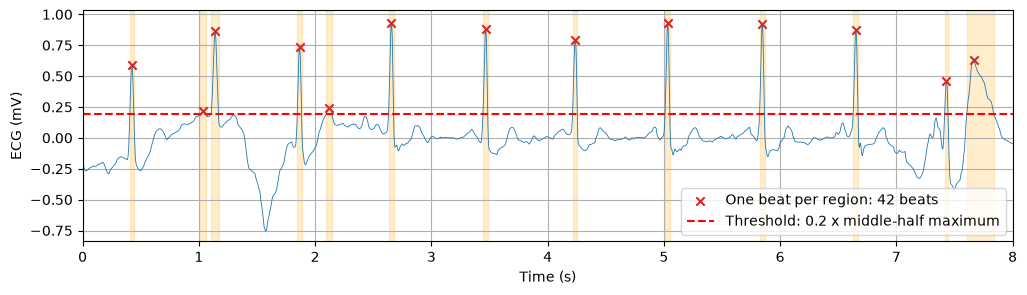

Naive: beat agreement 0.71 | heart rate error: MAE 51.7, P95 129.0 bpm | RMSSD error: MAE 319, P95 584 ms
  0 recordings with fewer than three of our beats have no RMSSD error.
  by label (agreement / HR MAE / RMSSD MAE): N 0.70 / 52.8 / 353 | A 0.76 / 48.1 / 182 | O 0.74 / 43.8 / 258 | ~ 0.48 / 110.2 / 627


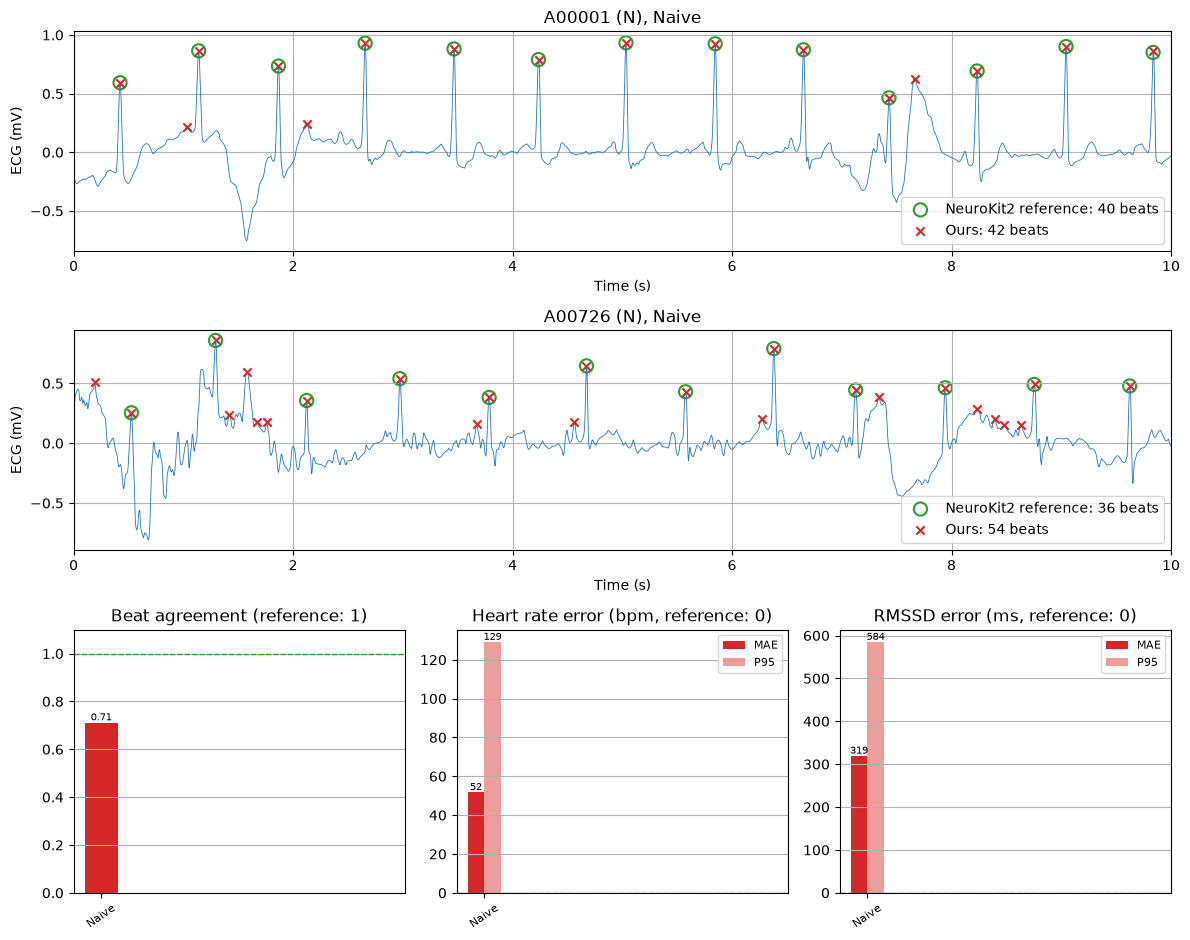

(np.float64(0.7111202074066568),
 np.float64(51.697652756292364),
 np.float64(129.0404706857481),
 np.float64(319.05823654865),
 np.float64(584.4505019316787))

In [8]:
threshold_fraction = 0.2

def find_regions(signal):
    """Regions where the signal is above threshold_fraction x its middle-half maximum.
    Returns (threshold, starts, stops); each region is signal[start:stop]."""
    n = len(signal)
    threshold = threshold_fraction * np.max(signal[n // 4:3 * n // 4])
    # +1 where the signal goes above the threshold, -1 just after it comes back below.
    edges = np.diff(np.r_[False, signal > threshold, False].astype(int))
    return threshold, np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)

def highest_in_regions(signal, starts, stops):
    """One beat per region, at its highest sample."""
    return np.array([a + np.argmax(signal[a:b]) for a, b in zip(starts, stops)], dtype=int)

steps_naive = {"regions": find_regions, "pick": highest_in_regions}

threshold, starts, stops = find_regions(raw)
fig, ax = plt.subplots()
plot_beats(ax, raw, ours=highest_in_regions(raw, starts, stops), labels={"ours": "One beat per region"},
           xlim=(start_s, end_s))
ax.axhline(threshold, color="red", ls="--", label=f"Threshold: {threshold_fraction:g} x middle-half maximum")
shade_regions(ax, starts, stops)
ax.legend(loc="lower right"); plt.show()

bench.score("Naive", steps_naive)

### 3.3 A beat detector that searches for the QRS complex
In this subsection we develop a QRS-searching detector, **detector v2**. Instead of looking for tall points, it looks for the *rapid changes* that characterise the QRS complex: the sharpest edges in every beat, whatever their height or sign. It grows out of your naive detector v1 in three steps, in the style of the QRS detector of Pan and Tompkins (1985):
1. **Denoise** with a band-pass filter, so that baseline drift and fast noise do not cross the threshold (Task 4A).
2. **Differentiate, square and integrate**, so that the signal measures speed rather than height and each QRS complex becomes one bump (Task 4B).
3. **Locate the R peak** inside each bump, back on the ECG (Task 4C).

Each step is introduced by the *problem* the previous detector still has, the *idea* that addresses it, and the *caveats* it brings, and each is scored against the NeuroKit2 reference across all 1,996 recordings, so that you see what it buys and what it costs. The figures follow recording `A00726` through every step.

#### Step 1: denoise with a band-pass filter
**Problem:** the baseline drifts (breathing, movement, electrode contact), and fast noise rides on the signal (muscle activity, mains interference). Neither comes from the heart's electrical activity, yet both can push the signal across a threshold.

**Idea:** keep the band where the ECG waves live, **0.5–40 Hz**, the bandwidth that monitoring ECGs have used for decades (Kligfield et al., 2007): below 0.5 Hz sits baseline wander from breathing and electrode movement, above 40 Hz sit muscle noise and mains hum. A Butterworth filter designed for **300 Hz** and applied forwards and backwards keeps the band without shifting any peak.

**Caveats:** the band is an assumption about where the ECG is. Real waveform features outside it are distorted too, and a corrupted segment stays corrupted.

This is an offline teaching filter: not the historical 1 kHz coefficients, and not necessarily Lab 2's cleaning method.

##### Task 4A — Code the filter · YOUR CODE
Write `bandpass`.

**Specification: `bandpass(x)`**
- **Given:** `x`, a 1-D NumPy array, the whole raw recording in mV at `FS` = 300 Hz, with baseline drift and fast noise on it. The settings `low_hz` and `high_hz` (0.5 and 40) are defined above the function.
- **You may use:** SciPy's `butter` and `sosfiltfilt`, imported at the top of the cell; their documentation gives the arguments.
- **Return:** a float array of the **same length**, the ECG filtered by a fourth-order Butterworth band-pass between `low_hz` and `high_hz` as second-order sections, applied forwards and then backwards so that no peak is shifted in time.
- **Checked by:** a reference implementation on your recording.

The cell checks it against a reference on your recording, plots raw against filtered, and scores `steps_4a` (naive + filter) on the leaderboard. Until it is done, later cells use the reference filter.

**What it buys:** a cleaner signal, but not a better score. The baseline is flatter and the small high-frequency noise outside the band is gone, but the threshold is still a test of *height*, and the things that fool it most, T waves, slow swings and inverted QRS complexes, are ECG and live inside the band. The filter comes first because of step 2: once height is turned into speed, any fast noise left in the signal is emphasised just as much as a QRS.

**Deliver:** the function with the check passed, and its leaderboard line.


In [9]:
from scipy.signal import butter, sosfiltfilt
from shared_ecg import filter_ecg  # Reference, used by the self-check (and by later cells until Task 4A is done).
low_hz, high_hz = 0.5, 40.0

def bandpass(x):
    """Fourth-order Butterworth bandpass, low_hz to high_hz, applied forwards and backwards."""
    sos = None       # YOUR CODE: the filter design, as second-order sections.
    filtered = None  # YOUR CODE: x filtered forwards and backwards.
    return filtered

done_4a = bandpass(raw) is not None
if not done_4a:
    print("Task 4A: complete the two expressions, then rerun this cell. Using the reference filter until then.")
    bandpass = lambda x: filter_ecg(x, FS, low_hz, high_hz)
else:
    np.testing.assert_allclose(bandpass(raw), filter_ecg(raw, FS, low_hz, high_hz))
    print("Self-check passed.")
steps_4a = {**steps_naive, "filter": bandpass}
clean = bandpass(raw)

if done_4a:
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(t, raw, alpha=0.6, label="Raw")
    ax.plot(t, clean, label=f"Filtered {low_hz:g}–{high_hz:g} Hz")
    ax.set(xlim=(start_s, end_s), xlabel="Time (s)", ylabel="ECG (mV)"); ax.legend(); plt.show()
    bench.score("+ filter", steps_4a)


Task 4A: complete the two expressions, then rerun this cell. Using the reference filter until then.


#### Step 2: differentiate, square and integrate
These three operations are **one group**: each prepares the signal for the next, and only together do they give the threshold what it needs, one bump per beat. You write them as two functions, `differentiate` and `envelope` (square, then integrate), but they enter the leaderboard as one step, named after what they produce: `+ envelope`.

**Problem:** height is a poor clue. In Task 3, a tall T wave or a drifting baseline could be as high as the R peak, and some recordings have a downward QRS.

**Idea:** what makes the QRS different is its **speed**. It rises and falls within a few tens of milliseconds, much faster than the P and T waves.
1. **Differentiate.** Subtracting neighbouring samples measures that speed: sharp edges give large differences, slow waves small ones. But each QRS now gives a large positive *and* a large negative difference (in the opposite order for a downward QRS), as several separate spikes with near-zero gaps between them, and the threshold would count each spike that crosses it.
2. **Square.** +5 and −5 both become 25, and large values grow much more than small ones (2 → 4, but 10 → 100), so the steep QRS stands out further from the gentle P and T waves.
3. **Integrate.** Average the squared values over a window about as long as a QRS complex, starting with **120 ms**, so that the spikes of one beat merge into one bump: an activity envelope. The window is rounded to an odd sample count so it is centred.

**Caveats:** fast noise is fast too: differentiating amplifies it, and squaring emphasises a strong noise spike just as much as a QRS. The window length is a trade-off, and the envelope is smeared in time. The centred average uses future samples and zero padding at the edges, so inspect boundary effects. This is an explicit 300 Hz teaching setting, not a reproduction of the historical seven-sample sum.

##### Task 4B — Code the envelope · YOUR CODE
Write `differentiate` and `envelope`.

**Specification: `differentiate(x)`**
- **Given:** `x`, the filtered ECG, a 1-D float array in mV.
- **You may use:** NumPy only.
- **Return:** `d`, a float array of the **same length**, with `d[n] = x[n] - x[n-1]` for every `n ≥ 1` and `d[0] = 0`.
- **Checked by:** the invented signal `[0, 1, 3, 1, 0]`, which must give `[0, 1, 2, -2, -1]`.

**Specification: `envelope(d)`**
- **Given:** `d`, the difference signal, a 1-D float array with positive and negative spikes at every QRS. The setting `integration_s` (0.12) is defined above the function.
- **You may use:** NumPy only, for example a convolution with a window of equal weights, or cumulative sums.
- **Return:** `averaged`, a non-negative float array of the **same length**: at each sample, the mean of `d ** 2` over a window of `width` samples centred on that sample, where `width` is `integration_s * FS` rounded to an integer and made odd (37 samples at 120 ms) so that it has a centre. Beyond the edges the signal counts as zero.
- **Checked by:** a reference implementation on your recording.

The cell checks both on an invented signal and against a reference, shows the four traces, and scores `steps_4b`.

**Deliver:** both functions with the checks passed, and the leaderboard line.


In [10]:
from shared_ecg import moving_average  # Reference, used by the self-check (and by later cells until Task 4B is done).
integration_s = 0.12

def differentiate(x):
    """Difference of neighbouring samples, d[n] = x[n] - x[n-1], with d[0] = 0 to keep the length."""
    d = None  # YOUR CODE: the difference signal, same length as x.
    return d

def envelope(d):
    """Square, then a centred moving average over integration_s (an odd number of samples)."""
    width = None     # YOUR CODE: the window length in samples, an odd integer.
    averaged = None  # YOUR CODE: the centred moving average of d ** 2.
    return averaged

practice_signal = np.array([0.0, 1.0, 3.0, 1.0, 0.0])
done_4b = differentiate(practice_signal) is not None and envelope(np.zeros(FS)) is not None
if not done_4b:
    print("Task 4B: complete the three expressions, then rerun this cell. Using the reference functions until then.")
    differentiate = lambda x: np.diff(x, prepend=x[0])
    envelope = lambda d: moving_average(d ** 2, FS, integration_s)
else:
    np.testing.assert_array_equal(differentiate(practice_signal), [0, 1, 2, -2, -1])
    np.testing.assert_allclose(envelope(differentiate(clean)), moving_average(differentiate(clean) ** 2, FS, integration_s))
    print("Self-checks passed.")
steps_4b = {**steps_4a, "differentiate": differentiate, "envelope": envelope}
difference = differentiate(clean)
activity = envelope(difference)
threshold, starts, stops = find_regions(activity)  # The same relative threshold as before.

if done_4b:
    axes = plot_traces({"Filtered ECG (mV)": clean, "Difference (mV/sample)": difference,
                        "Squared difference": difference ** 2, "Activity envelope": activity},
                       xlim=(start_s, end_s))
    axes[1].axhline(0, color="grey", lw=0.7)
    axes[3].axhline(threshold, color="red", ls="--", label="Threshold")
    shade_regions(axes[3], starts, stops); axes[3].legend(); plt.show()
    print("Candidate regions:", len(starts))
    bench.score("+ envelope", steps_4b)


Task 4B: complete the three expressions, then rerun this cell. Using the reference functions until then.


#### Step 3: locate the R peak on the ECG
**Problem:** the envelope says *roughly when* a beat happens, but its peak is not the R peak: after squaring and averaging it is smeared and can be offset. Timing matters, because RR intervals (Section 2) are differences between these times. And occasionally one beat still produces two regions.

**Idea:** go back to the filtered ECG and take its maximum in each candidate region. For an inverted recording, inspect the waveform and explicitly select negative polarity instead. Then apply a physiological rule: two beats cannot be closer than **250 ms**, so keep the stronger one.

**Caveats:** the 250 ms rule can reject true fast beats or keep strong artefacts. It is not the historical R/S rejection rule or a validated clinical detector.

##### Task 4C — Code the locator · YOUR CODE
Write `locate`.

**Specification: `locate(ecg, starts, stops)`**
- **Given:** `ecg`, the filtered ECG, a 1-D float array in mV; `starts` and `stops`, integer arrays of equal length in time order, where region `k` is `ecg[starts[k]:stops[k]]`, the regions do not overlap, and each should hold one beat but occasionally two regions fall on one beat. Inside the function `score` is already defined: `ecg` for positive polarity, `-ecg` for negative, so the beat is always the **highest** sample of `score`. The settings `polarity` and `min_separation_s` (0.25) are defined above the function.
- **You may use:** `highest_in_regions(signal, starts, stops)`, supplied in the detector v1 cell, which returns the index of the highest sample of each region; Python's sorting; NumPy.
- **Return:** a 1-D integer array of beat indices in **time order**, one candidate per region, with every candidate that lies closer than `min_separation_s * FS` samples to a *stronger* kept candidate removed. Going through the candidates strongest first guarantees that the stronger of two close candidates is the one kept.
- **Checked by:** an invented signal with peaks of height 5, 6 and 3 at samples 100, 150 and 500, which must give `[150, 500]`; and a reference implementation on your recording.

The cell checks it on an invented signal and against a reference, shows the kept beats on the filtered and raw ECG, and scores `steps_4c`.

**Deliver:** the function with the checks passed, and the leaderboard line.


In [11]:
from shared_ecg import locate_rpeaks  # Reference, used by the self-check (and by later cells until Task 4C is done).
polarity = "positive"   # Choose "negative" only after inspecting an inverted waveform.
min_separation_s = 0.25

def locate(ecg, starts, stops):
    """The highest ECG sample in each region (the lowest for negative polarity); of two beats
    closer than min_separation_s, keep the stronger."""
    score = ecg if polarity == "positive" else -ecg
    candidates = None       # YOUR CODE: the highest sample of score in each region.
    strongest_first = None  # YOUR CODE: the candidates, highest score first.
    if candidates is None or strongest_first is None:
        return None
    kept = []
    for peak in strongest_first:
        far_enough = None   # YOUR CODE: True if no kept beat is within min_separation_s * FS samples of peak.
        if far_enough is None:
            return None
        if far_enough:
            kept.append(peak)
    return np.array(sorted(kept), dtype=int)

practice_signal = np.zeros(1000)
practice_signal[[100, 150, 500]] = [5, 6, 3]  # Three regions; the first two are 50 samples apart.
done_4c = locate(practice_signal, [95, 145, 495], [105, 155, 505]) is not None
if not done_4c:
    print("Task 4C: complete the three expressions, then rerun this cell. Using the reference function until then.")
    locate = lambda ecg, a, b: locate_rpeaks(ecg, a, b, FS, min_separation_s, polarity)[1]
else:
    np.testing.assert_array_equal(locate(practice_signal, [95, 145, 495], [105, 155, 505]), [150, 500])
    np.testing.assert_array_equal(locate(clean, starts, stops),
                                  locate_rpeaks(clean, starts, stops, FS, min_separation_s, polarity)[1])
    print("Self-checks passed.")
steps_4c = {**steps_4b, "locate": locate}

if done_4c:
    region_maxima, peaks = highest_in_regions(clean, starts, stops), locate(clean, starts, stops)
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    plot_beats(axes[0], clean, candidates=region_maxima, ours=peaks, labels={"candidates": "Region maxima",
               "ours": "Kept"}, title="Filtered ECG")
    plot_beats(axes[1], raw, ours=peaks, labels={"ours": "Same times"}, title="Raw ECG", xlim=(start_s, end_s))
    plt.tight_layout(); plt.show()
    bench.score("+ locate", steps_4c)  # Positive polarity everywhere.


Task 4C: complete the three expressions, then rerun this cell. Using the reference function until then.


### 3.4 Median imputation: correcting the HRV estimate
**Problem:** after the three steps of 3.3 a few beats are still wrong: an artefact taken for a beat, or a small QRS that never crossed the threshold. Such an error barely affects the heart rate, but it does affect RMSSD, which squares the differences between successive intervals. With 800 ms intervals, one missed beat creates an interval of 1600 ms and two successive differences of ±800 ms, and RMSSD jumps from about 30 ms to about 210 ms.

**Idea:** a peak-finding or QRS-searching detector is agnostic of rhythm. It detects each beat from local features only, which makes it sensitive to noise: an artefact right after a beat becomes two beats in rapid succession, and a small QRS becomes none. Yet a human heart beats with a specific rhythm, and the beats around a doubtful one say a lot about whether it is real. Median imputation adds that rhythm. The **median RR** is the recording's typical interval, and a few wrong beats barely move it. Going through the beats in time order:
1. a beat closer than **0.6 × median RR** to the last kept beat is an extra detection: drop it;
2. a gap longer than **1.6 × median RR** hides missed beats: split it evenly into round(gap / median RR) intervals, inserting beats.

If the median rate is outside 30–200 bpm, most beats are wrong and the median cannot be trusted, so the beats are left unchanged. NeuroKit2 does not correct its beats by default, and the reference is NeuroKit2 as it is: it is **not** corrected. Where the reference has an error of its own, correcting ours moves us *away* from it.

**Caveats:** inserted beats are **invented**, evenly spaced, so they pull RMSSD down. A genuine premature beat is "corrected" away, and in atrial fibrillation the irregularity *is* the physiology. A single median for the whole recording assumes the rate is steady.

#### Task 4D — Code median imputation · YOUR CODE
Write `correct`.

**Specification: `correct(beats)`**
- **Given:** `beats`, a 1-D integer array of sample indices in time order, from detector 4C: usually 30 to 60 per recording, with occasionally an extra one (an artefact) or a missing one (a small QRS). The settings `correct_short` and `correct_long` (0.6 and 1.6) are defined above the function. The rate guard, the walk through the beats and the insertion of evenly spaced beats are supplied; you write the four quantities the rule needs.
- **You may use:** NumPy only.
- **Return:** a 1-D integer array in time order: the beats with every extra one dropped and every gap filled. `median_rr` is the median RR interval in samples; for each beat, `gap` (supplied) is its distance to the last kept beat; `too_close` is whether the gap is shorter than `correct_short * median_rr`; `too_far` is whether it is longer than `correct_long * median_rr`; `k` is the number of intervals the gap should hold, `gap / median_rr` rounded to an integer.
- **Checked by:** the invented beats `[0, 300, 600, 900, 1500, 1800, 1850, 2100]` (median RR 300), which must give `[0, 300, 600, 900, 1200, 1500, 1800, 2100]`; and a reference implementation on `A00726`.

The cell checks it on an invented beat sequence and against a reference, shows what it drops and inserts on `A00726`, and scores `steps_4d`.

**Deliver:** the function with the checks passed, and the leaderboard line.


In [12]:
from shared_ecg import correct_beats  # Reference, used by the self-check (and by later cells until Task 4D is done).
correct_short, correct_long = 0.6, 1.6

def correct(beats):
    """Median-RR rule, in time order: drop a beat closer than correct_short x median RR to the last
    kept beat; split a gap longer than correct_long x median RR evenly into round(gap / median RR)
    intervals. Leave the beats unchanged if the median rate is outside 30-200 bpm."""
    if not 30 <= median_rate_bpm(beats) <= 200:
        return beats
    median_rr = None  # YOUR CODE: the median RR interval, in samples.
    if median_rr is None:
        return None
    kept = [beats[0]]
    for beat in beats[1:]:
        gap = beat - kept[-1]
        too_close = None  # YOUR CODE: is the gap shorter than correct_short x median_rr?
        too_far = None    # YOUR CODE: is the gap longer than correct_long x median_rr?
        if too_close is None or too_far is None:
            return None
        if too_close:     # An extra detection.
            continue
        if too_far:       # Missed beats: fill the gap with evenly spaced beats.
            k = None      # YOUR CODE: the number of intervals the gap should hold, an integer.
            if k is None:
                return None
            kept += [int(kept[-1] + gap * j / k) for j in range(1, k)]
        kept.append(beat)
    return np.array(kept, dtype=int)

practice_beats = np.array([0, 300, 600, 900, 1500, 1800, 1850, 2100])  # Median RR 300: one gap, one extra.
done_4d = correct(practice_beats) is not None
if not done_4d:
    print("Task 4D: complete the four expressions, then rerun this cell. Using the reference function until then.")
    correct = lambda beats: correct_beats(beats, FS, correct_short, correct_long)
else:
    np.testing.assert_array_equal(correct(practice_beats), [0, 300, 600, 900, 1200, 1500, 1800, 2100])
steps_4d = {**steps_4c, "correct": correct}

demo_id = "A00726"  # N-labelled: one artefact taken for a beat, one small missed QRS.
x = signal_mv(ecg_data[demo_id])
before = run_detector(x, steps_4c)
after = correct(before)
if done_4d:
    np.testing.assert_array_equal(after, correct_beats(before, FS, correct_short, correct_long))
    print("Self-checks passed.")
    dropped, inserted = np.setdiff1d(before, after), np.setdiff1d(after, before)
    print(f"{demo_id}: median RR {1000 * np.median(np.diff(before)) / FS:.0f} ms; "
          f"dropped {len(dropped)}, inserted {len(inserted)}")
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    plot_beats(axes[0], x, ours=before, dropped=dropped, inserted=inserted,
               labels={"ours": "Detected (4C)", "inserted": "Inserted (invented)"})
    axes[1].plot(before[1:] / FS, 1000 * np.diff(before) / FS, ".-", label="RR before")
    axes[1].plot(after[1:] / FS, 1000 * np.diff(after) / FS, ".-", label="RR after")
    axes[1].set(ylabel="RR (ms)", xlabel="Time (s)"); axes[1].legend()
    plt.tight_layout(); plt.show()
    bench.score("+ correct", steps_4d, show=(record_id, demo_id), zoom_s=(0, 30))


Task 4D: complete the four expressions, then rerun this cell. Using the reference function until then.


### Optional: how close did we get?
This part is not in the lab note; run it if you are curious. The leaderboard shows the gap after each step. The scores summarise all recordings at once, and an MAE far above the median error says that a few recordings carry most of it. To see *how* the remaining disagreements are distributed, for the final detector compare one **heart rate** and one **RMSSD** per recording with the reference's, each from that detector's own beats (ours after imputation, the reference as it is). Recordings where either median rate is outside 30–200 bpm are counted as detection failures, not compared: there is no plausible rhythm to measure. The comparison is supplied; nothing is entered on the leaderboard. It answers the question that matters for Section 2 and for Section 4: would your heart rate and RMSSD change if you had used the other detector?

- **Bland–Altman plot:** for each recording, the difference (reference − ours) against the mean of the two. The **bias** is the mean difference; the **95% limits of agreement** are bias ± 1.96 SD of the differences.
- **Pearson's r** measures how well the points fit *any* straight line.
- **Lin's CCC** measures how well they fit the *identity* line, so a bias or a scale difference lowers it.

Why not correlate the beat times themselves? They always increase, so two detectors' beat times correlate almost perfectly even when they disagree badly. These numbers describe **agreement, not accuracy**: both detectors can make the same mistake.


Recordings compared: 1943; detection failures (median rate outside 30–200 bpm): 53

Heart rate (bpm), reference − ours:
  all: n=1943 | bias    -0.7 | limits    -22.2 to    20.8 | r=0.84 CCC=0.83 | median |diff|   0.3 | MAE   3.8 | P95   18.6
    N: n=1159 | bias    -0.1 | limits    -15.3 to    15.0 | r=0.81 CCC=0.80 | median |diff|   0.1 | MAE   2.2 | P95    8.4
    A: n= 190 | bias    -3.3 | limits    -24.0 to    17.5 | r=0.92 CCC=0.90 | median |diff|   2.0 | MAE   5.3 | P95   24.3
    O: n= 539 | bias     0.3 | limits    -22.6 to    23.3 | r=0.88 CCC=0.87 | median |diff|   0.9 | MAE   5.0 | P95   25.4
    ~: n=  55 | bias   -13.4 | limits    -77.8 to    50.9 | r=0.08 CCC=0.04 | median |diff|   8.9 | MAE  20.6 | P95   98.3

RMSSD (ms), reference − ours:
  all: n=1943 | bias    68.8 | limits   -251.8 to   389.4 | r=0.51 CCC=0.34 | median |diff|  20.5 | MAE  80.5 | P95  338.7
    N: n=1159 | bias    44.8 | limits   -250.0 to   339.7 | r=0.44 CCC=0.26 | median |diff|   7.2 | MAE  58.7 |

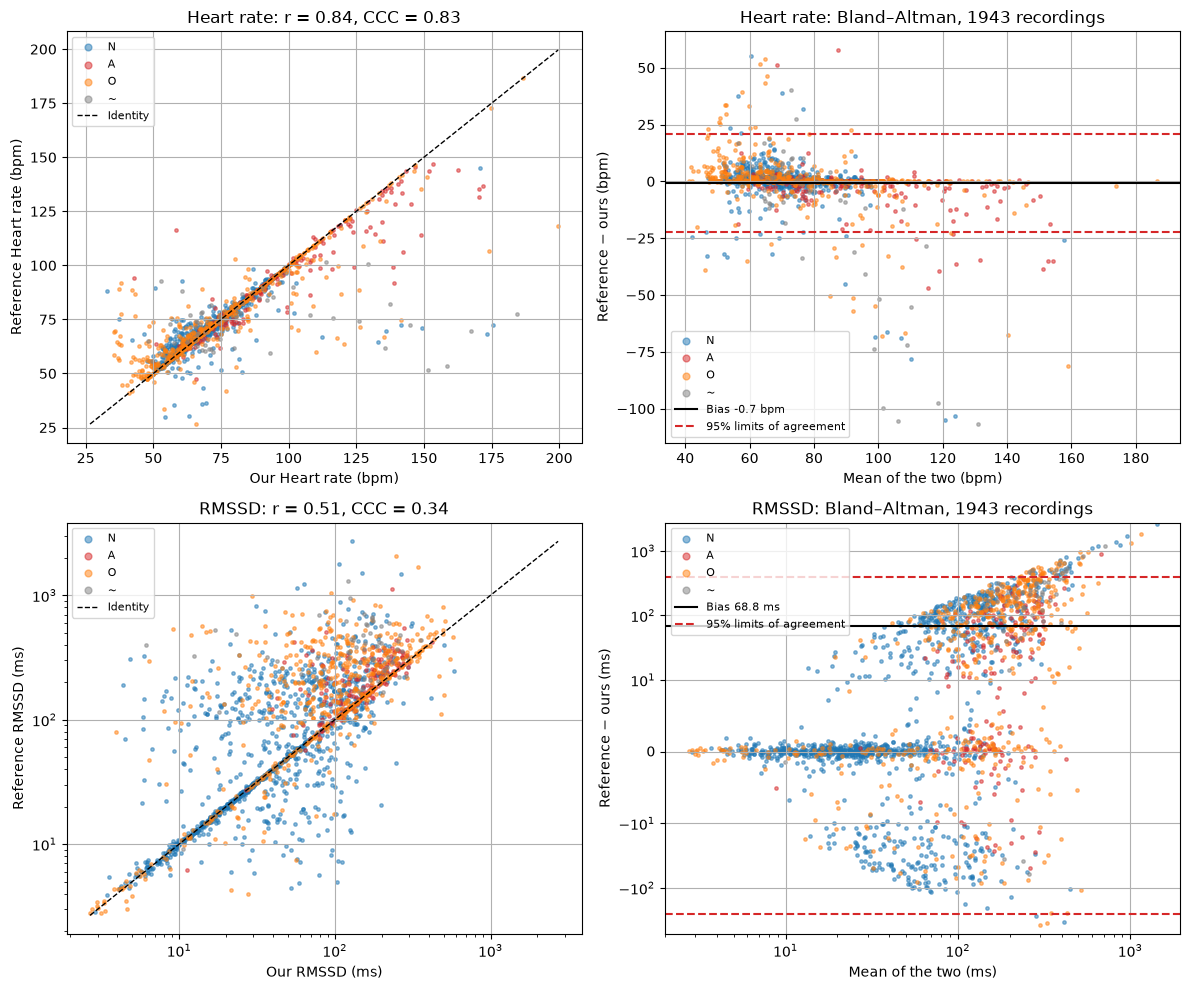

In [13]:
# Heart rate and RMSSD per recording, ours (final detector) vs the NeuroKit2 reference (about 5 s).
comparison = bench.compare(steps_4d)

#### Take one out
Adding steps one at a time shows what each step adds *on top of the ones before it*. The reverse test asks whether each step is still needed once all the others are there: remove one step from the full detector and score it again. The supplied function does this for every step and plots the gaps next to the full detector's (about 30 s; nothing is entered on the leaderboard). Removing the filter costs little, as adding it gained little; removing differentiate, square and integrate costs most, although adding the filter before it gained almost nothing: a step's value depends on which other steps are present.


All steps: beat agreement 0.90 | heart rate error: MAE 5.0, P95 28.5 bpm | RMSSD error: MAE 146, P95 393 ms


Without filter: beat agreement 0.90 | heart rate error: MAE 4.9, P95 28.5 bpm | RMSSD error: MAE 152, P95 397 ms


Without diff, square & integrate: beat agreement 0.81 | heart rate error: MAE 20.0, P95 89.3 bpm | RMSSD error: MAE 132, P95 408 ms


Without locate: beat agreement 0.92 | heart rate error: MAE 5.7, P95 30.5 bpm | RMSSD error: MAE 176, P95 417 ms


Without correct: beat agreement 0.91 | heart rate error: MAE 5.1, P95 31.7 bpm | RMSSD error: MAE 194, P95 604 ms


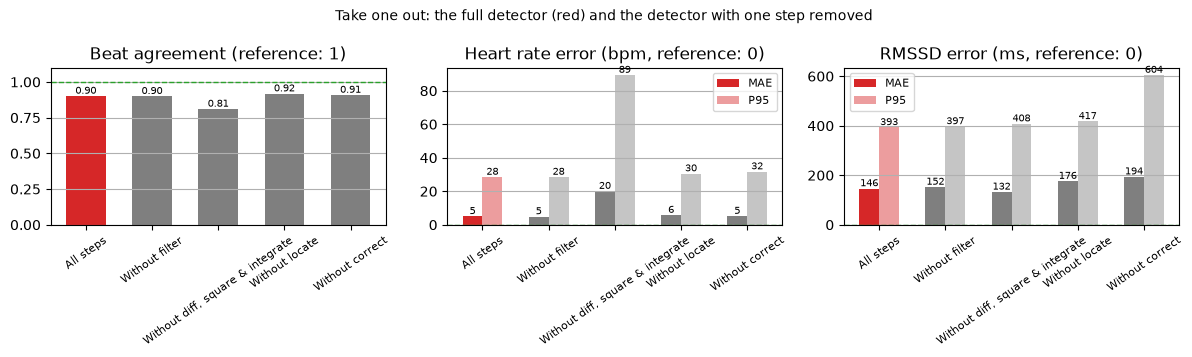

In [14]:
take_one_out = bench.take_one_out(steps_4d)


## 4. Classifying rhythms with ECG features
In clinical practice, wearable ECGs are often used to detect heart problems that a clinic visit might miss. Atrial fibrillation is the main one: it often comes and goes, is often silent, raises the risk of stroke about fivefold, and can be treated once it is found. So people record short strips at home, by the million, and no cardiologist can read them all. In this section we use the two features of Section 3, heart rate and RMSSD, together with the other ECG features a library extracts, to predict the rhythm of each recording: N, A, O or ~. That prediction is the triage: likely AF goes to a clinician, noise is recorded again, normal is filed. The label is a screening flag, not a diagnosis. The 2017 challenge that produced this dataset was set up for exactly this task.

**Requirements:** NeuroKit2 (≥0.2.13, from `requirements.txt`) and scikit-learn, from `requirements-comparison.txt`, and the precomputed feature table `ECG_feature.pkl` next to `ECG.pkl`.


### 4.1 NeuroKit2 ECG features
**From two features to the full set.** In Section 3 you extracted two features, heart rate and RMSSD, with a detector you built. They are two of many. Once the beats are known, and the P, Q, S and T waves around each of them, a library can measure a whole family of numbers from the same recording (Table 2 of the lab note): how the RR intervals around each beat compare with one another (8 R-peak timing features); how far apart the waves of a beat are in time and in amplitude, which is the shape of the beat rather than its timing (20 wave-shape features); the 25 HRV features, which generalise RMSSD (`HRV_MeanNN` is the mean interval, so heart rate is 60 000 / MeanNN, and `HRV_RMSSD` is your RMSSD); and 1 signal quality index. Section 2 showed that RMSSD alone already separates N from A to a useful degree, but O overlaps both and ~ is scattered, so no single threshold will do. A classifier combines all 54 and draws the boundary itself. The route is interpretable, you can ask which features the classifier relies on, and it learns from about 1,400 labelled recordings. Its price is that every new problem needs new expertise and new features. Lab 2 asks what happens when nobody designs them.

**How they are extracted.** `extract_feature`, from Lab 2's `ECG_feature_utils.py`, runs the reference pipeline of Section 3 (`ecg_clean`, then `ecg_peaks`, no correction), locates the P, Q, S and T waves around each beat with `ecg_delineate`, and returns the 54 numbers. It runs on the whole recording without visual review: that is what makes 2,000 recordings feasible, and it is the risk: nobody checks the beats.


In [15]:
from ECG_feature_utils import extract_feature
from shared_ecg import list_feature_names

stored = ecg_data[record_id]["data"]  # Stored units, as used for the precomputed table.
features_one = extract_feature(stored, FS)
feature_names = list_feature_names(stored, FS)  # In the order extract_feature returns them.
if len(feature_names) != len(features_one):
    raise ValueError("Feature names do not match: check the NeuroKit2 version (>=0.2.13).")
print(f"{record_id}: {len(features_one)} features, e.g.")
for name in ["ecg_RRm", "HRV_SDNN", "HRV_RMSSD", "SQI"]:
    print(f"  {name:10s} {features_one[feature_names.index(name)]:.3f}")


A00001: 54 features, e.g.
  ecg_RRm    0.761
  HRV_SDNN   43.371
  HRV_RMSSD  34.586
  SQI        1.000


### 4.2 Training a RandomForest with the features
We will train a RandomForest of 100 trees on the 54 features and use it to predict the rhythm of unseen ECG recordings. The data are already prepared: running `extract_feature` on all 2,000 recordings takes a long time, so the table was computed in advance with the same function (its rows follow the order of `ECG.pkl`; rows where extraction failed are all zeros). The cell below makes **the same split as Lab 2** (70% train, 15% validation, 15% test, `random_state=42`), so that Lab 2 can compare its routes with yours, and encodes the labels as integers. Because the classes are unbalanced, the evaluation metric is the **macro-averaged F1**: the mean of the four classes' F1 scores, so that each class counts equally. A reference training gives accuracy 0.79 and a macro F1 of 0.64 on the test set (Table 3 of the lab note).


In [16]:
from shared_ecg import load_feature_table
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

FEATURE_PATH = Path(DATA_PATH).with_name("ECG_feature.pkl")  # From the same data zip.
features_all, labels_all = load_feature_table(FEATURE_PATH, ecg_data, trusted=TRUST_DATA_SOURCE)
if features_all is not None:
    print("Feature table:", features_all.shape,
          "| all-zero rows (extraction failed):", int((~features_all.any(axis=1)).sum()))
    row = features_all[list(ecg_data).index(record_id)]
    print("5A reproduces this recording's row:", bool(np.allclose(features_one, row)))
    le = LabelEncoder()
    y = le.fit_transform(labels_all)  # N, A, O, ~ as integers; le.classes_ gives the names back.
    # Same split as Lab 2: 70% train, then the remaining 30% halved into validation and test.
    idx_train, idx_temp = train_test_split(np.arange(len(y)), test_size=0.3, random_state=42)
    idx_val, idx_test = train_test_split(idx_temp, test_size=0.5, random_state=42)
    print(f"Split: {len(idx_train)} train, {len(idx_val)} validation, {len(idx_test)} test; classes {list(le.classes_)}")


Feature table: (2000, 54) | all-zero rows (extraction failed): 4
5A reproduces this recording's row: True
Split: 1400 train, 300 validation, 300 test; classes [np.str_('A'), np.str_('N'), np.str_('O'), np.str_('~')]


#### Task 5 — Code the classifier · YOUR CODE
Write `train_forest` and `predict`.

**Specification: `train_forest(x_train, y_train)`**
- **Given:** `x_train`, a 2-D float array of 1,400 rows (recordings) × 54 columns (features), unscaled, with ranges that differ by orders of magnitude between columns; `y_train`, an integer array of 1,400 class codes (0 to 3, from `le.classes_`).
- **You may use:** `StandardScaler` and `RandomForestClassifier`, imported at the top of the cell; their documentation gives the arguments.
- **Return:** `(scaler, model)`: a scaler fitted on `x_train` **only** (each column centred and scaled by the training set's mean and standard deviation), and a forest of 100 trees with `random_state=42`, fitted on the scaled `x_train` and `y_train`.

**Specification: `predict(scaler, model, x)`**
- **Given:** the two fitted objects, and `x`, a 2-D array of n rows × 54 unscaled features.
- **Return:** an integer array of n predicted class codes, from `x` scaled with the **same** scaler.
- **Checked by:** the reference model's predictions on the 300 test recordings, which yours must match exactly.

The cell checks your predictions on the test set against a reference, prints the classification report for the validation and test sets, and plots the ten features the forest uses most.

**Analysing the result.** Which features does the forest rely on? Half of the importance sits in the 25 HRV features and another fifth in the 8 RR-timing features; the ten most used are all rhythm features, led by SDRMSSD, CVSD and RMSSD, which measure how much the intervals vary. That agrees with the definition of atrial fibrillation in Section 1: the rhythm is *irregularly irregular*, so what separates A is the intervals, not the waves. Your test macro F1 is what Lab 2 compares its networks with.

**Deliver:** both functions with the check passed; the test report; and your test macro F1, written down for Lab 2.


In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score
from sklearn.preprocessing import StandardScaler
from shared_ecg import train_reference_forest  # Reference, used only by the self-check.

def train_forest(x_train, y_train):
    """Standardise with the training set only, then fit a RandomForest of 100 trees (random_state=42)."""
    scaler = None  # YOUR CODE: the scaler fitted on x_train.
    model = None   # YOUR CODE: the forest fitted on the scaled x_train.
    return scaler, model

def predict(scaler, model, x):
    """The model's predicted classes for the features x, scaled with the same scaler."""
    return None    # YOUR CODE: the predicted classes of x, scaled with the same scaler.

model = None
if features_all is None:
    print("Task 5 needs the feature table of 5B.")
else:
    scaler, model = train_forest(features_all[idx_train], y[idx_train])
    if scaler is None or model is None or predict(scaler, model, features_all[idx_test]) is None:
        print("Task 5: complete the three expressions, then rerun this cell.")
        model = None
    else:
        ref_scaler, ref_model = train_reference_forest(features_all[idx_train], y[idx_train])
        np.testing.assert_array_equal(predict(scaler, model, features_all[idx_test]),
                                      ref_model.predict(ref_scaler.transform(features_all[idx_test])))
        print("Self-check passed.")
        for name, part in [("Validation", idx_val), ("Test", idx_test)]:
            predicted = predict(scaler, model, features_all[part])
            print(f"{name} set (macro F1 {f1_score(y[part], predicted, average='macro'):.3f}):")
            print(classification_report(y[part], predicted, target_names=le.classes_))
        test_macro_f1 = f1_score(y[idx_test], predict(scaler, model, features_all[idx_test]), average="macro")
        print(f"Your test macro F1: {test_macro_f1:.3f}. Write it down for Lab 2.")
        top = np.argsort(model.feature_importances_)[::-1][:10]
        plt.figure(figsize=(8, 3.5))
        plt.barh([feature_names[i] for i in top][::-1], model.feature_importances_[top][::-1])
        plt.xlabel("Importance (mean decrease in impurity)")
        plt.title("The ten features the forest uses most")
        plt.tight_layout(); plt.show()


Task 5: complete the three expressions, then rerun this cell.


## Submit your completed workbook
Save this notebook with your code and plots. Restart the kernel and run all cells to check that your work is reproducible.

- [ ] Task 1: the five wave diagrams labelled, with the check passed.
- [ ] Task 2: `rhythm_features` passing the NeuroKit2 check on the three recordings.
- [ ] Task 3: `naive_beats` passing both checks, with the plot.
- [ ] Tasks 4A–4D: `bandpass`, `differentiate` and `envelope`, `locate` and `correct` passing their checks, with the leaderboard.
- [ ] Task 5: `train_forest` and `predict` passing the check, the test report, and your test macro F1.

**Bridge to Lab 2:** you have built the hand-crafted route end to end, from an ECG signal to interpretable features to a predicted label. Lab 2 asks what happens when nobody designs the features: a network trained from scratch on the same split, and a model pretrained on millions of ECGs. Keep your test macro F1 to compare with them.
